# Case iFood · Parte 1: análise exploratória e tratamento dos dados

**Autor:** Victor Maurício · **Notebook 1 de 3** ·
[Parte 2: segmentação](02_segmentacao_clientes.ipynb) ·
[Parte 3: modelo de propensão e lucro](03_modelo_propensao_e_lucro.ipynb)

## 1. Contexto

O case de Analista de Dados do iFood simula uma empresa de varejo de alimentos que vende cinco categorias
de produtos (vinhos, carnes, frutas, peixes e doces), além de uma linha *gold*, por três canais: lojas físicas,
catálogo e site. Para testar a venda de um novo gadget, a empresa fez uma **campanha piloto** com
**2.240 clientes escolhidos aleatoriamente**, contatados por telefone:

| | Valor |
|---|---|
| Custo da campanha (3 MU por contato) | 6.720 MU |
| Receita (11 MU por cliente que aceitou) | 3.674 MU |
| Taxa de aceite | 15% |
| **Lucro** | **−3.046 MU** |

O case pede três entregáveis, divididos entre os notebooks deste projeto:

1. **Entender as características dos clientes que aceitaram a oferta** (este notebook);
2. **Segmentar os clientes** com base no comportamento ([Parte 2](02_segmentacao_clientes.ipynb));
3. **Construir um modelo de classificação que maximize o lucro da próxima campanha** ([Parte 3](03_modelo_propensao_e_lucro.ipynb)).

O enunciado completo está em [`referencias/case_ifood.md`](../referencias/case_ifood.md).

### Por que começar pela análise exploratória

A análise exploratória de dados (EDA) é a etapa em que conhecemos a base antes de modelar: conferimos tipos,
valores ausentes e registros inconsistentes, entendemos a distribuição de cada variável e levantamos hipóteses
sobre o que se relaciona com o comportamento dos clientes. As decisões tomadas aqui (quais registros remover,
quais variáveis criar e como tratar cada coluna) determinam a qualidade da segmentação e do modelo
nas etapas seguintes.

In [1]:
from platform import python_version

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from matplotlib.cm import ScalarMappable
from matplotlib.colors import CenteredNorm, ListedColormap
from matplotlib.ticker import PercentFormatter

from src.auxiliares import inspecionar_outliers
from src.config import DADOS_ORIGINAIS, DADOS_TRATADOS
from src.graficos import pairplot, salvar_figura

sns.set_theme(style="whitegrid", palette="tab10")

print(f"Python {python_version()}")
for biblioteca in (pd, np, matplotlib, sns):
    print(f"{biblioteca.__name__:<12} {biblioteca.__version__}")

Python 3.13.5
pandas       2.3.3
numpy        2.3.5
matplotlib   3.10.0
seaborn      0.13.2


## 2. Primeiro contato com os dados

A base tem 2.240 clientes e 29 colunas, agrupadas em dados pessoais, gastos por categoria nos últimos dois anos,
compras por canal e respostas às campanhas de marketing. O significado de cada coluna está no
[dicionário de dados](../referencias/01_dicionario_de_dados.md). O arquivo original é separado por tabulação.

In [2]:
df = pd.read_csv(DADOS_ORIGINAIS, sep="\t")

with pd.option_context("display.max_columns", None):
    display(df.head())

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [3]:
bruto = pd.read_csv(DADOS_ORIGINAIS, sep="\t")
bruto

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [ ]:
with pd.option_context("display.float_format", "{:.2f}".format, "display.max_columns", None):
    display(df.describe())

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.00,2240.00,2216.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00,2240.00
mean,5592.16,1968.81,52247.25,0.44,0.51,49.11,303.94,26.30,166.95,37.53,27.06,44.02,2.33,4.08,2.66,5.79,5.32,0.07,0.07,0.07,0.06,0.01,0.01,3.00,11.00,0.15
std,3246.66,11.98,25173.08,0.54,0.54,28.96,336.60,39.77,225.72,54.63,41.28,52.17,1.93,2.78,2.92,3.25,2.43,0.26,0.26,0.26,0.25,0.11,0.10,0.00,0.00,0.36
min,0.00,1893.00,1730.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.00,11.00,0.00
25%,2828.25,1959.00,35303.00,0.00,0.00,24.00,23.75,1.00,16.00,3.00,1.00,9.00,1.00,2.00,0.00,3.00,3.00,0.00,0.00,0.00,0.00,0.00,0.00,3.00,11.00,0.00
50%,5458.50,1970.00,51381.50,0.00,0.00,49.00,173.50,8.00,67.00,12.00,8.00,24.00,2.00,4.00,2.00,5.00,6.00,0.00,0.00,0.00,0.00,0.00,0.00,3.00,11.00,0.00
75%,8427.75,1977.00,68522.00,1.00,1.00,74.00,504.25,33.00,232.00,50.00,33.00,56.00,3.00,6.00,4.00,8.00,7.00,0.00,0.00,0.00,0.00,0.00,0.00,3.00,11.00,0.00
max,11191.00,1996.00,666666.00,2.00,2.00,99.00,1493.00,199.00,1725.00,259.00,263.00,362.00,15.00,27.00,28.00,13.00,20.00,1.00,1.00,1.00,1.00,1.00,1.00,3.00,11.00,1.00


In [ ]:
display(df.describe(exclude="number"))
df["Marital_Status"].value_counts()

,Education,Marital_Status,Dt_Customer
count,2240,2240,2240
unique,5,8,663
top,Graduation,Married,31-08-2012
freq,1127,864,12


Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

### 2.1 O que chama atenção

- **`Year_Birth` tem mínimo em 1893.** Pela data dos cadastros (2012 a 2014), isso daria clientes com mais de
  120 anos, o que indica erro de preenchimento.
- **`Income` chega a 666.666**, muito acima do terceiro quartil (cerca de 68 mil). O valor com dígitos repetidos
  também sugere preenchimento inválido.
- **`Income` tem 24 valores ausentes** (1,1% da base). É a única coluna com nulos.
- **`Z_CostContact` e `Z_Revenue` não estão no dicionário e têm desvio padrão zero**: valem sempre 3 e 11.
  Coincidem com o custo por contato e a receita por aceite do case (6.720 / 2.240 = 3 MU e
  3.674 / 334 = 11 MU). Não servem como variável explicativa, mas usamos esses valores na análise de lucro.
- **A média de `Response` é 0,149**: 15% dos clientes aceitaram a oferta, como informado no case.
  A base é desbalanceada, o que vai pesar na escolha de métricas do modelo.
- **`Marital_Status` tem 8 categorias**, incluindo respostas como "Absurd", "YOLO" e "Alone" (7 registros).
  Vamos agrupá-las.
- **`Dt_Customer` está como texto** e precisa ser convertida para data.

## 3. Visão geral das distribuições

Antes de tratar a base, vale olhar a distribuição de todas as colunas numéricas de uma vez.

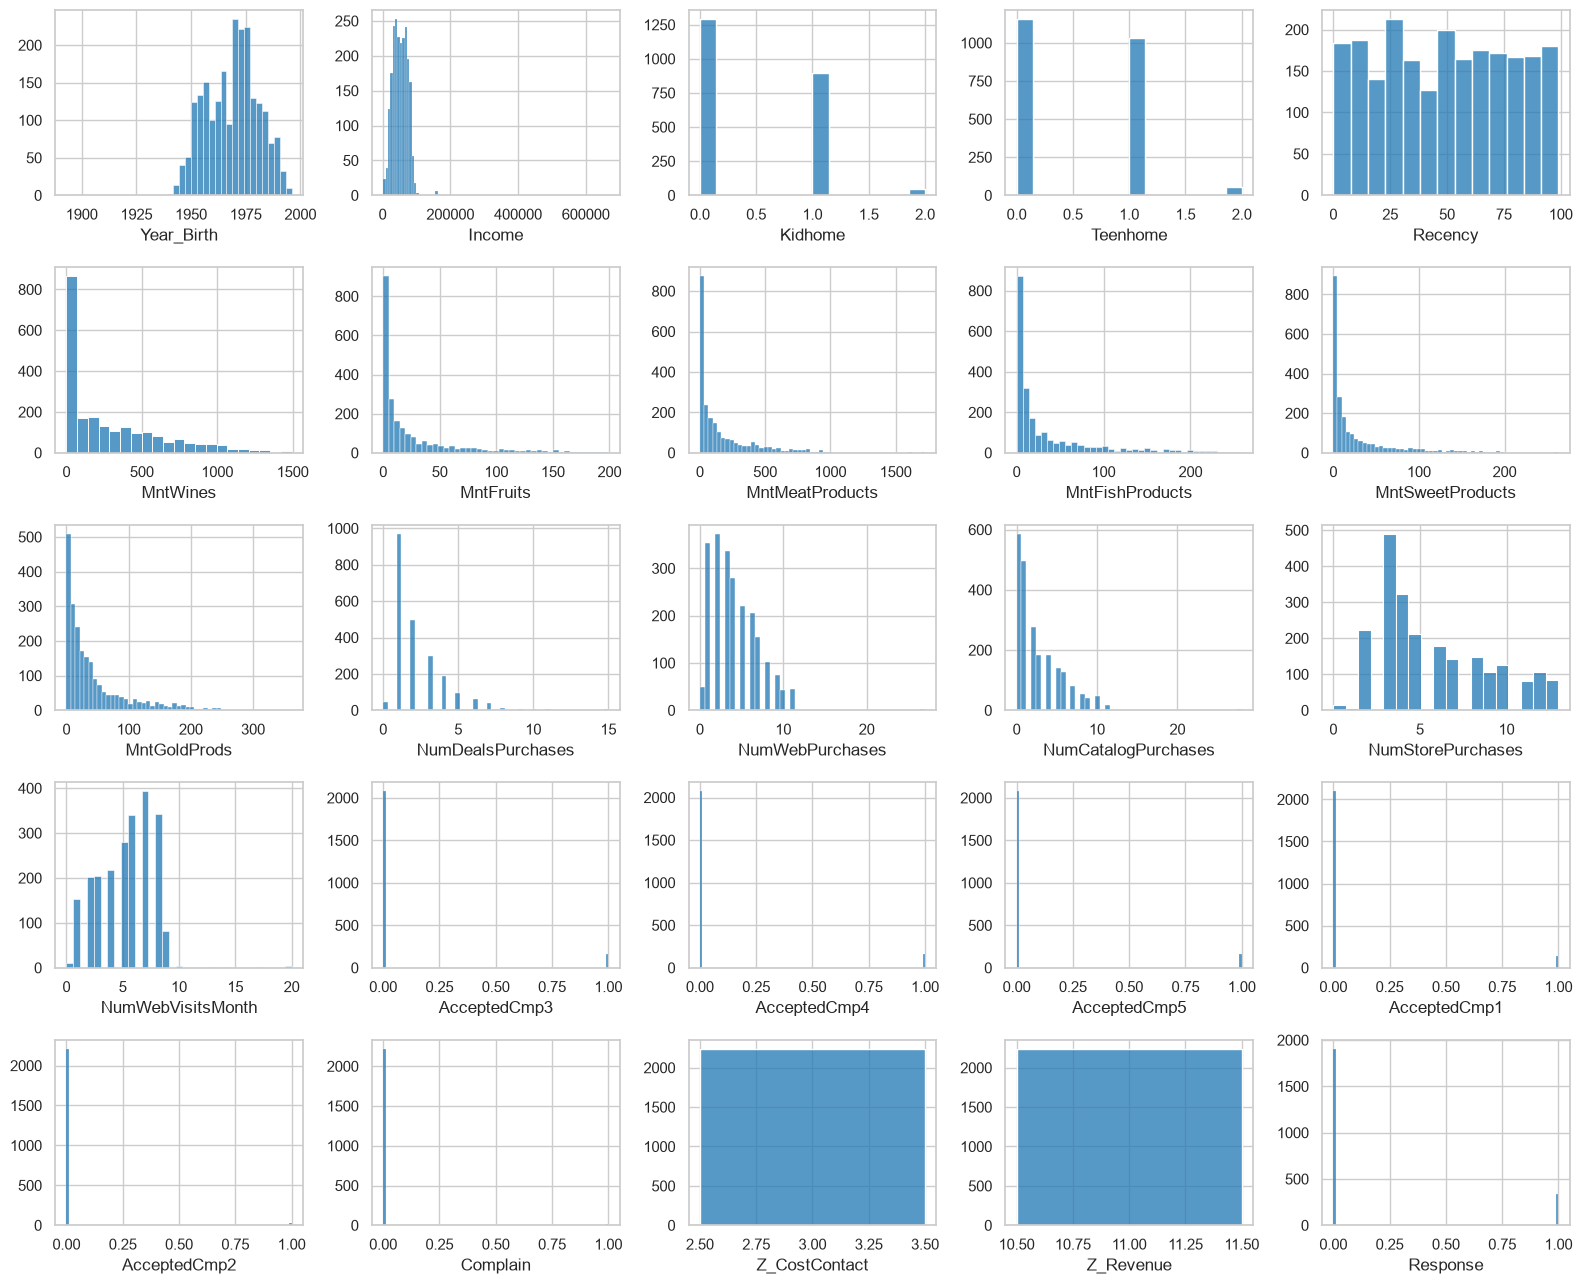

In [ ]:
colunas_numericas = df.select_dtypes("number").columns.drop("ID")

fig, axs = plt.subplots(5, 5, figsize=(16, 13))

for ax, coluna in zip(axs.flatten(), colunas_numericas):
    sns.histplot(data=df, x=coluna, ax=ax)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

**Principais achados:**

- **Gastos (`Mnt*`) e compras (`Num*`) são muito assimétricos à direita:** a maioria dos clientes gasta pouco e
  poucos gastam muito. Essas colunas vão precisar de uma transformação antes de entrar em modelos sensíveis
  à escala, como o K-Means e a regressão logística.
- **Os zeros nas colunas de gasto significam que o cliente não comprou aquela categoria**, e não dado ausente:
  a proporção de zeros é pequena e coerente com o restante da distribuição.
- **`Recency`** (dias desde a última compra) é aproximadamente uniforme entre 0 e 99 dias.
- **`Year_Birth`** tem formato próximo de uma normal, exceto pelos poucos registros anteriores a 1901.
- **As campanhas anteriores tiveram aceite baixo**, entre 1% e 7% cada. A campanha piloto (`Response`) teve 15%.
- **`Complain`**: menos de 1% dos clientes reclamou nos últimos dois anos.
- **`Kidhome` e `Teenhome`** assumem só os valores 0, 1 e 2 e se comportam como variáveis categóricas.

## 4. Tratamento e criação de variáveis

### 4.1 Registros duplicados

O `ID` é único, mas isso não garante que não haja clientes repetidos. Comparando todas as outras colunas:

In [ ]:
duplicadas = df.drop(columns="ID").duplicated()

print(f"Linhas idênticas a outra (exceto pelo ID): {duplicadas.sum()} ({duplicadas.mean():.1%} da base)")

colunas_sem_id_e_alvo = df.columns.drop(["ID", "Response"])
mesmas_features = df.duplicated(subset=colunas_sem_id_e_alvo)
print(f"Linhas com as mesmas características, mas resposta diferente: {mesmas_features.sum() - duplicadas.sum()}")

Linhas idênticas a outra (exceto pelo ID): 182 (8.1% da base)
Linhas com as mesmas características, mas resposta diferente: 19


**182 linhas (8%) são cópias exatas de outra**, com o mesmo ano de nascimento, data de cadastro, renda, gastos
nas seis categorias e respostas às seis campanhas. É improvável que dois clientes reais coincidam em todas essas
informações, então tratamos as cópias como duplicação de registros.

Mantê-las faria a mesma informação pesar duas vezes. Na modelagem, o problema é maior: uma cópia pode cair no
treino e a outra na validação, e o modelo seria avaliado em um cliente que já viu, o que infla as métricas.
**Removemos as duplicatas e mantivemos a primeira ocorrência.**

Há ainda 19 linhas com características iguais às de outra, mas com `Response` diferente. Elas não são cópias
exatas e foram mantidas: representam o ruído natural de clientes parecidos que tomaram decisões diferentes.

In [ ]:
df = df[~duplicadas]

df.shape

(2058, 29)

### 4.2 Valores ausentes e datas

Os 24 clientes sem renda representam 1,2% da base. Como a renda é uma das variáveis mais importantes da análise
e imputar um valor (pela mediana, por exemplo) poderia distorcer justamente os perfis que queremos descobrir,
optamos por **remover esses registros**.

Em seguida, convertemos `Dt_Customer` para data. O formato é dia-mês-ano.

In [ ]:
df = df.dropna()

df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")

df["Dt_Customer"].agg(["min", "max"])

min   2012-07-30
max   2014-06-29
Name: Dt_Customer, dtype: datetime64[us]

Os cadastros vão de julho de 2012 a junho de 2014. Como não há data de referência no case, assumimos que os dados
foram extraídos logo após o último cadastro e usamos **a data mais recente da base como referência** para
calcular idade e tempo de cadastro.

### 4.3 Novas variáveis

| Nova coluna | Como é calculada | Motivo |
|---|---|---|
| `DaysSinceEnrolled` | Dias entre o cadastro do cliente e o cadastro mais recente da base | Tempo de relacionamento em formato numérico (o modelo não usa datas diretamente) |
| `YearsSinceEnrolled` | `DaysSinceEnrolled // 365` | Versão em anos completos (0 ou 1), mais fácil de comunicar |
| `Age` | Ano do cadastro mais recente (2014) − `Year_Birth` | Idade na época da coleta, mais intuitiva que o ano de nascimento |
| `AgeGroup` | Faixas 18-30, 31-45, 46-60 e 61+ | Permite comparar perfis por faixa etária |
| `MntTotal` | Soma dos seis gastos (`Mnt*`) | Gasto total do cliente em dois anos |
| `MntRegularProds` | `MntTotal − MntGoldProds` | Separa os produtos regulares dos *gold* |
| `Children` | `Kidhome + Teenhome` | Total de dependentes, já que não sabemos o corte de idade entre criança e adolescente |
| `HasChildren` | 1 se `Children > 0` | Indicador de ter ou não dependentes |
| `AcceptedCmpTotal` | Soma das cinco campanhas anteriores aceitas | Engajamento histórico com marketing |
| `HasAcceptedCmp` | 1 se aceitou pelo menos uma campanha | Indicador de cliente que já respondeu a uma campanha |
| `NumTotalPurchases` | Compras pelo site + catálogo + loja | Total de compras, independentemente do canal |

Duas decisões merecem explicação:

- **Produtos *gold*:** o case diz que as cinco categorias "podem ser divididas" em produtos *gold* e regulares,
  mas `MntGoldProds` não é a soma de nenhuma combinação das outras colunas. Interpretamos que os cinco gastos
  por categoria são os produtos regulares e que `MntGoldProds` é uma linha à parte. Em um processo real,
  esse é o tipo de dúvida que levaríamos à área de negócio.
- **`NumDealsPurchases` fica fora do total de compras**, porque compras com desconto podem ter sido feitas em
  qualquer canal e já estariam contadas em `NumWebPurchases`, `NumCatalogPurchases` ou `NumStorePurchases`.
  O mesmo vale para `NumWebVisitsMonth`: visitar o site não é comprar.

In [ ]:
data_referencia = df["Dt_Customer"].max()

df["DaysSinceEnrolled"] = (data_referencia - df["Dt_Customer"]).dt.days
df["YearsSinceEnrolled"] = df["DaysSinceEnrolled"] // 365

df["Age"] = data_referencia.year - df["Year_Birth"]
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[18, 30, 45, 60, df["Age"].max()],
    labels=["18-30", "31-45", "46-60", "61+"],
    include_lowest=True,
)

colunas_gastos = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds",
]
df["MntTotal"] = df[colunas_gastos].sum(axis=1)
df["MntRegularProds"] = df["MntTotal"] - df["MntGoldProds"]

df["Children"] = df["Kidhome"] + df["Teenhome"]
df["HasChildren"] = (df["Children"] > 0).astype(int)

colunas_campanhas = [f"AcceptedCmp{i}" for i in range(1, 6)]
df["AcceptedCmpTotal"] = df[colunas_campanhas].sum(axis=1)
df["HasAcceptedCmp"] = (df["AcceptedCmpTotal"] > 0).astype(int)

df["NumTotalPurchases"] = (
    df["NumWebPurchases"] + df["NumCatalogPurchases"] + df["NumStorePurchases"]
)

df[["DaysSinceEnrolled", "YearsSinceEnrolled", "Age", "MntTotal", "Children", "AcceptedCmpTotal", "NumTotalPurchases"]].describe().round(1)

,DaysSinceEnrolled,YearsSinceEnrolled,Age,MntTotal,Children,AcceptedCmpTotal,NumTotalPurchases
count,2034.0,2034.0,2034.0,2034.0,2034.0,2034.0,2034.0
mean,352.4,0.5,45.2,607.6,1.0,0.3,12.6
std,202.5,0.5,12.0,603.6,0.7,0.7,7.2
min,0.0,0.0,18.0,5.0,0.0,0.0,0.0
25%,178.0,0.0,37.0,69.0,0.0,0.0,6.0
50%,351.5,0.0,44.0,397.0,1.0,0.0,12.0
75%,528.0,1.0,55.0,1048.0,1.0,0.0,18.0
max,699.0,1.0,121.0,2525.0,3.0,4.0,32.0


### 4.4 Simplificação do estado civil

Agrupamos `Marital_Status` em duas categorias: **`Partner`** (casado ou morando junto) e **`Single`**
(solteiro, divorciado, viúvo e as respostas "Alone", "Absurd" e "YOLO"). A distinção que interessa para o
comportamento de compra é se o cliente divide ou não a casa com um parceiro.

Mantivemos os cinco níveis de `Education`. Uma dúvida é o nível **"2n Cycle"**: no Processo de Bolonha ele
equivale ao mestrado, mas na seção 7 veremos que a renda desse grupo é menor que a do grupo "Master".
Por isso não juntamos as duas categorias.

In [ ]:
df["Marital_Status"] = df["Marital_Status"].replace(
    {
        "Married": "Partner",
        "Together": "Partner",
        "Single": "Single",
        "Divorced": "Single",
        "Widow": "Single",
        "Alone": "Single",
        "Absurd": "Single",
        "YOLO": "Single",
    }
)

df["Marital_Status"].value_counts()

Marital_Status
Partner    1302
Single      732
Name: count, dtype: int64

## 5. Outliers

Outliers são valores muito distantes do restante dos dados. Usamos o critério do boxplot (Tukey): é outlier
o valor abaixo de Q1 − 1,5 × IQR ou acima de Q3 + 1,5 × IQR, em que Q1 e Q3 são o primeiro e o terceiro
quartis e IQR = Q3 − Q1 é o intervalo interquartil.

Ser outlier estatístico não significa ser erro. Por isso seguimos quatro etapas:

1. Visualizar os boxplots de idade, renda e gasto total;
2. Inspecionar os registros fora dos limites com a função `inspecionar_outliers`
   (em [`src/auxiliares.py`](src/auxiliares.py));
3. Decidir, caso a caso, se o registro é inválido (remover) ou só incomum (manter);
4. Conferir os boxplots depois do tratamento.

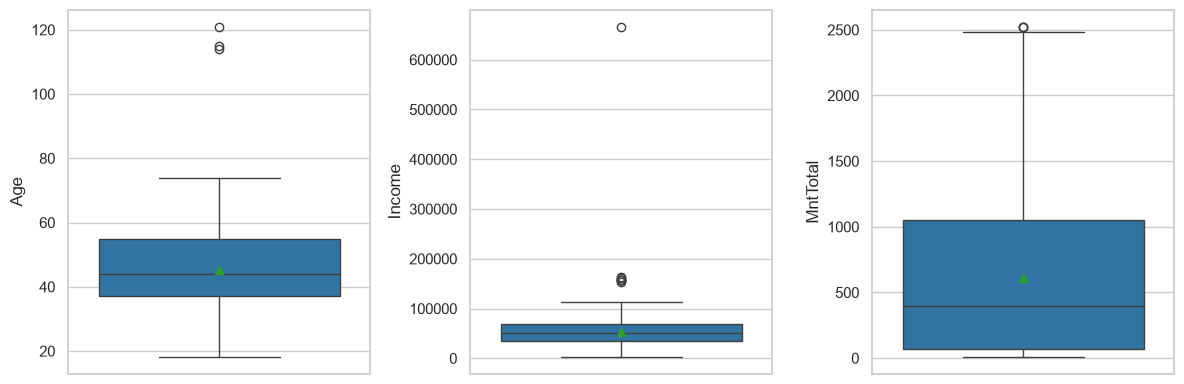

In [ ]:
colunas_outliers = ["Age", "Income", "MntTotal"]

fig, axs = plt.subplots(1, 3, figsize=(12, 4), tight_layout=True)

for ax, coluna in zip(axs, colunas_outliers):
    sns.boxplot(data=df, y=coluna, ax=ax, showmeans=True)

plt.show()

**Idade:** três clientes teriam entre 114 e 121 anos (nascidos em 1893, 1899 e 1900). São clientes ativos, com
compras registradas, mas a idade é implausível. Removemos esses três registros.

In [ ]:
inspecionar_outliers(df, "Age")[["ID", "Year_Birth", "Age", "Income", "MntTotal", "NumTotalPurchases"]]

,ID,Year_Birth,Age,Income,MntTotal,NumTotalPurchases
192,7829,1900,114,36640.0,65,5
239,11004,1893,121,60182.0,22,3
339,1150,1899,115,83532.0,1853,14


In [ ]:
df = df.drop(inspecionar_outliers(df, "Age").index)

**Renda:** oito clientes estão acima do limite superior. Além do 666.666, os outros sete (entre 153 mil e
162 mil) têm comportamento incoerente com a renda declarada:

- quatro gastaram menos de 110 MU em dois anos e quase não compraram;
- três gastaram entre 1.600 e 1.730 MU, quase tudo em carne, com 22 a 28 compras por catálogo e nenhuma
  compra pelo site.

Como são 0,4% da base e distorceriam a padronização da renda (que pesa muito na segmentação), removemos
os oito registros.

In [ ]:
outliers_renda = inspecionar_outliers(df, "Income")

outliers_renda[
    ["ID", "Income", "MntTotal", "MntMeatProducts", "NumCatalogPurchases",
     "NumStorePurchases", "NumWebPurchases", "NumDealsPurchases"]
].sort_values("Income", ascending=False)

,ID,Income,MntTotal,MntMeatProducts,NumCatalogPurchases,NumStorePurchases,NumWebPurchases,NumDealsPurchases
2233,9432,666666.0,62,18,1,3,3,4
617,1503,162397.0,107,16,0,1,0,0
687,1501,160803.0,1717,1622,28,1,0,15
1300,5336,157733.0,59,9,0,1,1,0
164,8475,157243.0,1608,1582,22,0,0,15
1653,4931,157146.0,1730,1725,28,0,0,0
2132,11181,156924.0,8,2,0,0,0,0
655,5555,153924.0,6,1,0,0,0,0


In [ ]:
df = df.drop(outliers_renda.index)

**Gasto total:** os três registros fora do limite estão muito perto dele e têm renda alta (88 mil a 91 mil),
compatível com o gasto. São clientes incomuns, não erros, e **foram mantidos**.

In [ ]:
inspecionar_outliers(df, "MntTotal")[["ID", "Income", "MntTotal", "NumTotalPurchases", "Age"]]

,ID,Income,MntTotal,NumTotalPurchases,Age
1179,5735,90638.0,2525,17,23
1492,1763,87679.0,2524,28,26
1572,5350,90638.0,2525,17,23


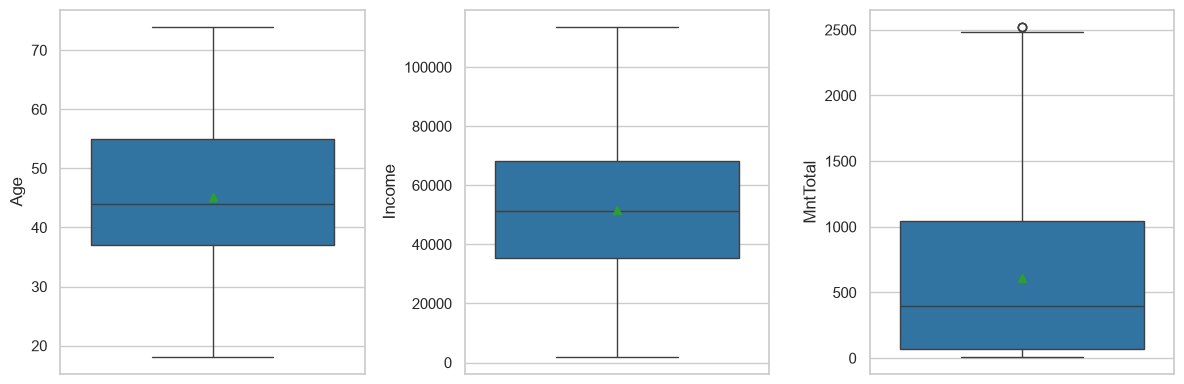

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4), tight_layout=True)

for ax, coluna in zip(axs, colunas_outliers):
    sns.boxplot(data=df, y=coluna, ax=ax, showmeans=True)

plt.show()

## 6. Base tratada

Removemos as colunas que não agregam à análise:

- `Year_Birth` e `Dt_Customer`, substituídas por `Age`, `AgeGroup`, `DaysSinceEnrolled` e `YearsSinceEnrolled`;
- `Z_CostContact` e `Z_Revenue`, que são constantes.

O `ID` vira o índice da tabela: não é usado como variável, mas permite rastrear cada cliente.
A base tratada é salva em Parquet, que preserva os tipos (como a ordem das faixas de `AgeGroup`).

In [ ]:
df = df.drop(columns=["Year_Birth", "Dt_Customer", "Z_CostContact", "Z_Revenue"]).set_index("ID")

print(f"{df.shape[0]} clientes e {df.shape[1]} colunas")
print(f"Taxa de aceite da campanha piloto: {df['Response'].mean():.1%}")

df.to_parquet(DADOS_TRATADOS)

2023 clientes e 35 colunas
Taxa de aceite da campanha piloto: 15.4%


Saímos de 2.240 para **2.023 clientes** (217 removidos: 182 duplicados, 24 sem renda, 3 com idade inválida e 8 com renda
inconsistente). A taxa de aceite se manteve em 15%.

## 7. Análise exploratória

### 7.1 Renda, gastos e filhos

O pairplot mostra a distribuição de cada variável (diagonal) e a relação entre pares de variáveis,
separando clientes com e sem filhos.

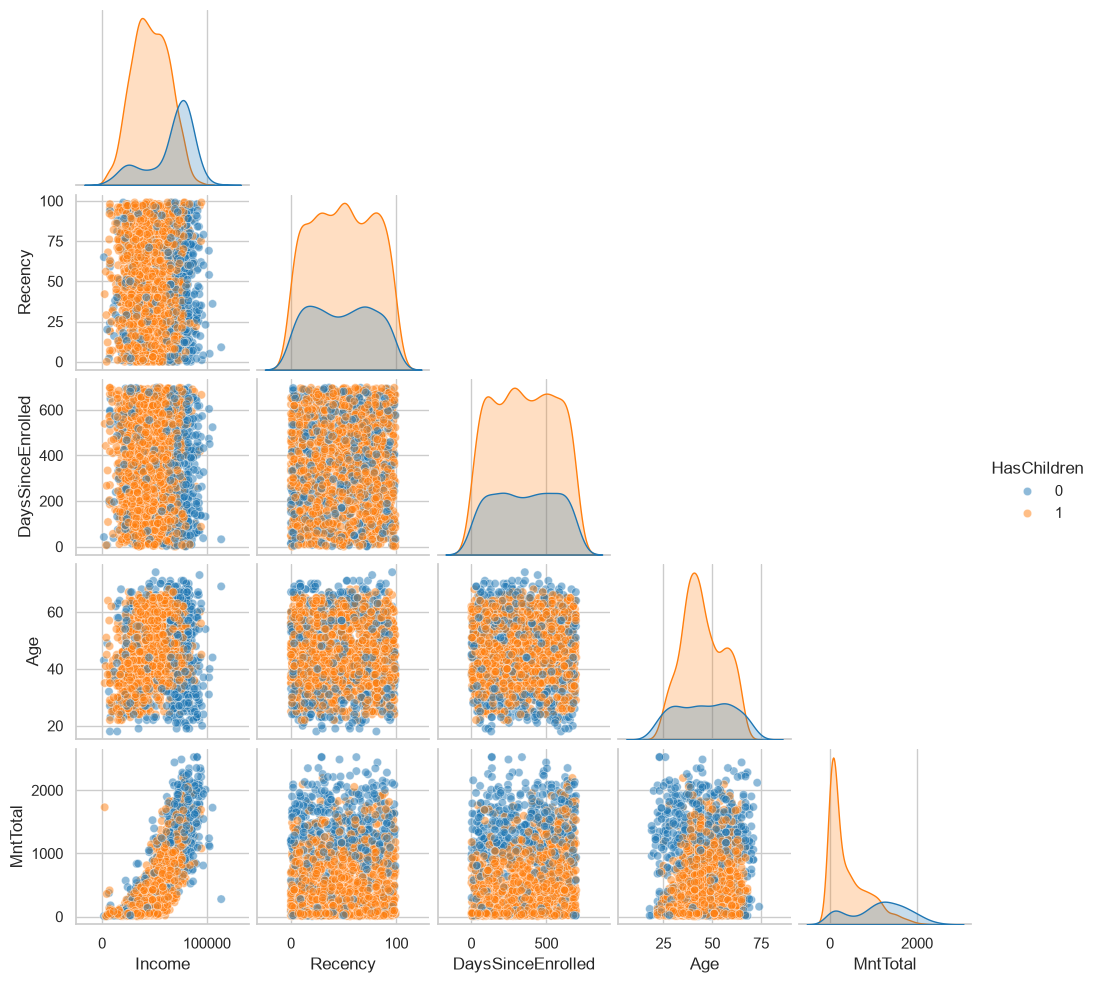

In [ ]:
colunas_analise = ["Income", "Recency", "DaysSinceEnrolled", "Age", "MntTotal"]

pairplot(df, colunas_analise, coluna_hue="HasChildren")

In [ ]:
print(f"Correlação entre renda e gasto total: {df['Income'].corr(df['MntTotal']):.2f}")

df.groupby("HasChildren")[["Income", "MntTotal"]].median()

Correlação entre renda e gasto total: 0.82


,Income,MntTotal
HasChildren,,
0,72298.0,1192.0
1,45947.5,206.0


- **Renda e gasto andam juntos** (correlação de 0,82): quanto maior a renda, maior o gasto total.
- **Ter filhos muda o perfil:** clientes sem filhos têm renda mediana de 72 mil contra 46 mil de quem tem
  filhos, e gastam quase seis vezes mais (mediana de 1.192 MU contra 206 MU).
- `Recency` e `DaysSinceEnrolled` têm distribuições parecidas nos dois grupos.
- Entre os clientes com filhos há um pico de idade perto dos 40 anos.

### 7.2 Renda por escolaridade, idade e estado civil

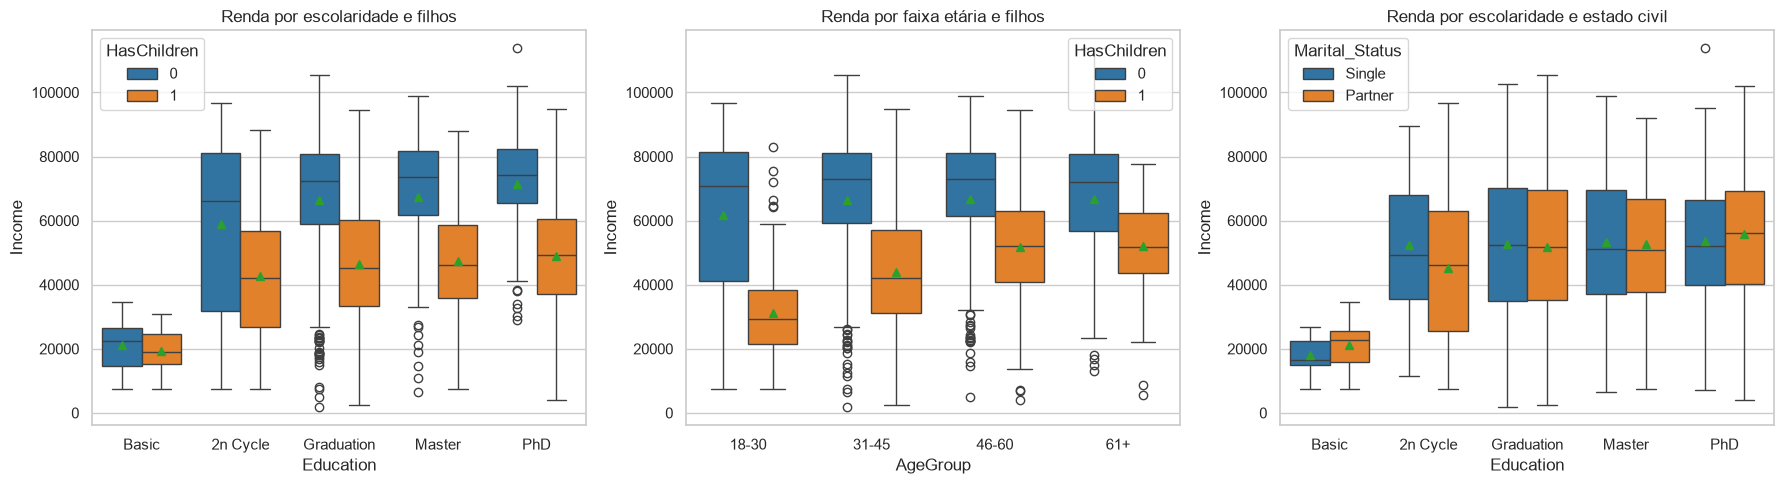

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5), tight_layout=True)

ordem_educacao = ["Basic", "2n Cycle", "Graduation", "Master", "PhD"]

sns.boxplot(data=df, x="Education", y="Income", hue="HasChildren", order=ordem_educacao, showmeans=True, ax=axs[0])
sns.boxplot(data=df, x="AgeGroup", y="Income", hue="HasChildren", showmeans=True, ax=axs[1])
sns.boxplot(data=df, x="Education", y="Income", hue="Marital_Status", order=ordem_educacao, showmeans=True, ax=axs[2])

axs[0].set_title("Renda por escolaridade e filhos")
axs[1].set_title("Renda por faixa etária e filhos")
axs[2].set_title("Renda por escolaridade e estado civil")

plt.show()

- **A renda cresce com a escolaridade e com a idade.** O grupo "Basic" tem a menor renda (mediana de 20 mil) e a
  renda mediana sobe de 37 mil (18-30 anos) para 59 mil (61+).
- **Em todos os níveis de escolaridade e em todas as faixas etárias, quem não tem filhos tem renda maior.**
  Ter filhos é um dos fatores que mais diferenciam os clientes.
- **O estado civil não separa a renda:** as caixas de `Partner` e `Single` são muito parecidas na maioria dos níveis.
- O "2n Cycle" tem renda mediana (47 mil) abaixo da do "Master" (51 mil), o que reforça a decisão de não juntar
  as duas categorias.

### 7.3 Produtos regulares e *gold*

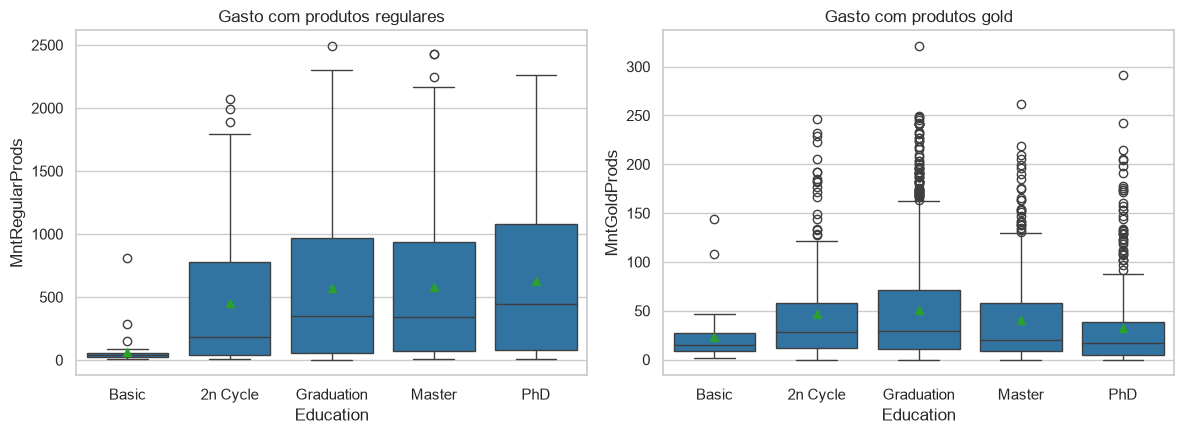

Participação dos produtos gold no gasto total: 7.2%


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), tight_layout=True)

sns.boxplot(data=df, x="Education", y="MntRegularProds", order=ordem_educacao, showmeans=True, ax=axs[0])
sns.boxplot(data=df, x="Education", y="MntGoldProds", order=ordem_educacao, showmeans=True, ax=axs[1])

axs[0].set_title("Gasto com produtos regulares")
axs[1].set_title("Gasto com produtos gold")

plt.show()

print(f"Participação dos produtos gold no gasto total: {df['MntGoldProds'].sum() / df['MntTotal'].sum():.1%}")

Os produtos *gold* representam só 7% do gasto total e **não seguem o padrão da renda**: o grupo com doutorado tem o
maior gasto com produtos regulares, mas uma das menores medianas de gasto com *gold* (só acima do grupo "Basic"). Como a coluna tem muitos outliers e
valores baixos, evitamos tirar conclusões fortes sobre ela.

### 7.4 Quem aceitou a campanha piloto?

Este é o primeiro entregável do case: entender as características de quem respondeu à oferta.
Os gráficos abaixo mostram a taxa de aceite em cada grupo de clientes. A linha tracejada é a taxa geral (15%).

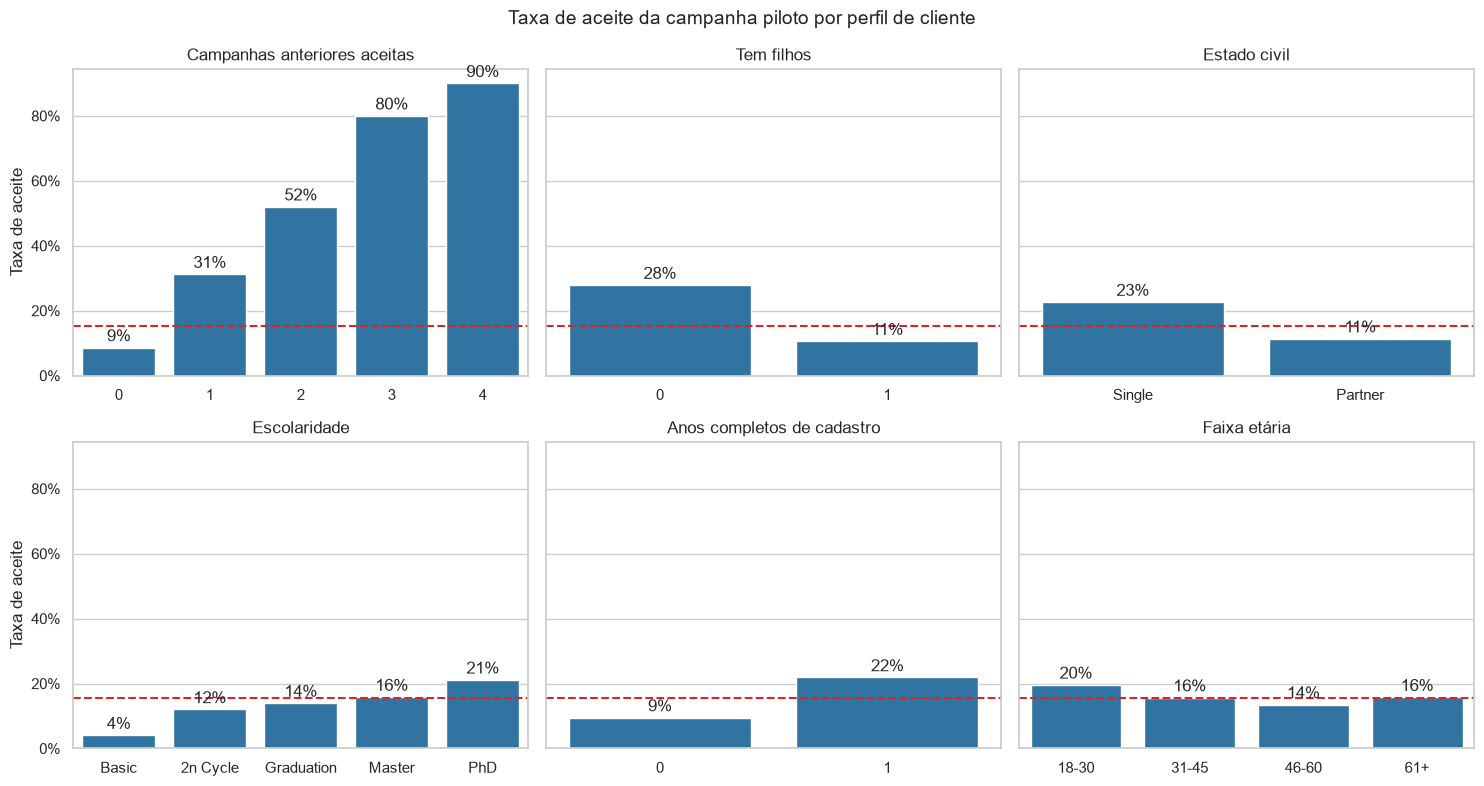

In [ ]:
colunas_perfil = {
    "AcceptedCmpTotal": "Campanhas anteriores aceitas",
    "HasChildren": "Tem filhos",
    "Marital_Status": "Estado civil",
    "Education": "Escolaridade",
    "YearsSinceEnrolled": "Anos completos de cadastro",
    "AgeGroup": "Faixa etária",
}
taxa_geral = df["Response"].mean()

fig, axs = plt.subplots(2, 3, figsize=(15, 8), sharey=True)

for ax, (coluna, titulo) in zip(axs.flatten(), colunas_perfil.items()):
    ordem = ordem_educacao if coluna == "Education" else None
    sns.barplot(data=df, x=coluna, y="Response", order=ordem, errorbar=None, color="tab:blue", ax=ax)
    ax.axhline(taxa_geral, color="tab:red", linestyle="--")
    ax.bar_label(ax.containers[0], fmt=lambda v: f"{v:.0%}", padding=2)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("Taxa de aceite")

fig.suptitle("Taxa de aceite da campanha piloto por perfil de cliente", fontsize=14)
plt.tight_layout()
salvar_figura(fig, "taxa_aceite_por_perfil.png")
plt.show()

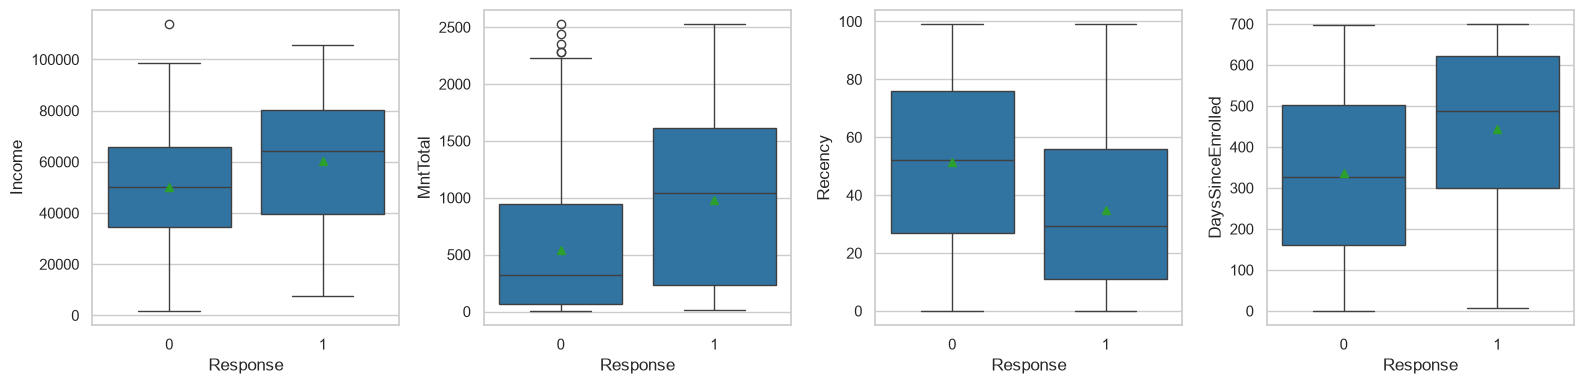

,Income,MntTotal,Recency,DaysSinceEnrolled,NumCatalogPurchases
Response,,,,,
0,50127.0,317.0,52.0,327.0,1.0
1,64044.0,1041.0,29.5,486.5,4.0


In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(16, 4), tight_layout=True)

for ax, coluna in zip(axs, ["Income", "MntTotal", "Recency", "DaysSinceEnrolled"]):
    sns.boxplot(data=df, x="Response", y=coluna, showmeans=True, ax=ax)

plt.show()

df.groupby("Response")[["Income", "MntTotal", "Recency", "DaysSinceEnrolled", "NumCatalogPurchases"]].median()

**Perfil de quem aceitou a oferta:**

- **Histórico de campanhas é o sinal mais forte.** A taxa de aceite vai de 9% entre quem nunca aceitou uma
  campanha para 31% (uma campanha), 52% (duas), 80% (três) e 90% (quatro).
- **Clientes sem filhos aceitam 2,6 vezes mais** (28% contra 11%).
- **Solteiros aceitam o dobro** dos que têm parceiro (23% contra 11%), mesmo sem diferença de renda entre os grupos.
- **Escolaridade:** a taxa vai de 4% ("Basic") a 21% ("PhD").
- **Clientes mais antigos aceitam mais:** 22% entre quem tem um ano ou mais de cadastro, contra 10%.
- **Quem aceitou tem renda maior** (mediana de 64 mil contra 50 mil), **gasta 3,3 vezes mais**
  (1.041 MU contra 317 MU) e **comprou mais recentemente** (30 dias desde a última compra contra 52).
- A faixa etária diferencia pouco: todas ficam entre 14% e 20%, com a maior taxa entre os mais jovens (18-30).

### 7.5 Correlação das variáveis com a resposta

Para comparar todas as variáveis na mesma escala, transformamos as categóricas em colunas binárias
(`get_dummies`) e calculamos a correlação de Pearson de cada uma com `Response`.

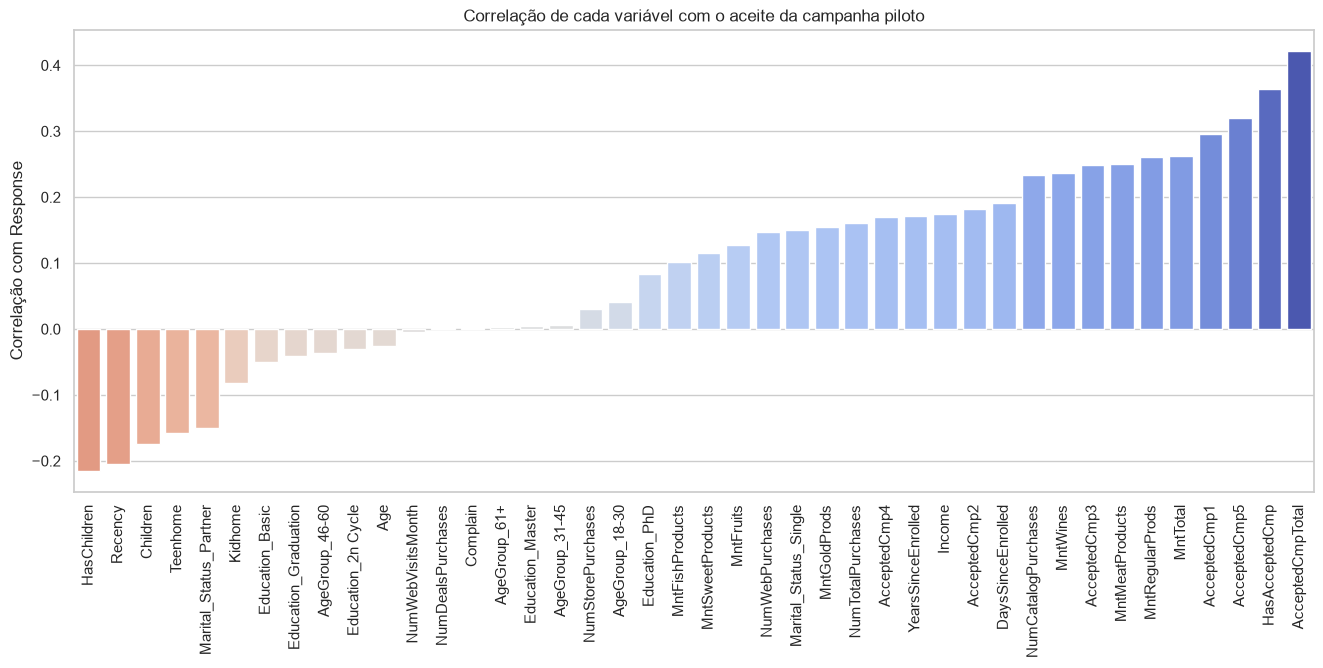

In [ ]:
df_dummies = pd.get_dummies(df, dtype="int8")

correlacao_resposta = (
    df_dummies.corr()["Response"].drop("Response").sort_values().to_frame("corr")
)

# cores centralizadas em zero: vermelho para correlação negativa, azul para positiva
mapa_cores = ScalarMappable(norm=CenteredNorm(vcenter=0, halfrange=0.4), cmap="coolwarm_r")
cores = ListedColormap([mapa_cores.to_rgba(valor) for valor in correlacao_resposta["corr"]]).colors

fig, ax = plt.subplots(figsize=(16, 6))

sns.barplot(
    data=correlacao_resposta,
    x=correlacao_resposta.index,
    y="corr",
    hue=correlacao_resposta.index,
    palette=cores,
    legend=False,
    ax=ax,
)
ax.tick_params(axis="x", rotation=90)
ax.set_xlabel("")
ax.set_ylabel("Correlação com Response")
ax.set_title("Correlação de cada variável com o aceite da campanha piloto")

salvar_figura(fig, "correlacao_com_resposta.png")
plt.show()

As correlações confirmam em números o que os gráficos mostraram: `AcceptedCmpTotal` (0,42) e as campanhas 5 e 1
são as mais associadas ao aceite, seguidas pelos gastos (`MntTotal`, 0,26) e pelo gasto com carnes.
`HasChildren` e `Recency` (ambas perto de −0,2) são as correlações negativas mais fortes.

Nenhuma correlação passa de 0,5 e a de Pearson só capta relações lineares de uma variável por vez.
Por isso o modelo da Parte 3 combina todas as variáveis ao mesmo tempo.

## 8. Conclusões da análise exploratória

1. **Engajamento passado prevê engajamento futuro:** quem já aceitou campanhas tem taxa de aceite muito maior.
   É a informação mais valiosa para direcionar a próxima campanha.
2. **Renda e gasto andam juntos** e são maiores entre quem aceitou a oferta.
3. **Ter filhos é um divisor de perfis:** reduz renda, gasto e propensão a aceitar a oferta.
4. **Recência e tempo de cadastro importam:** clientes que compraram há pouco tempo e que estão há mais tempo
   na base respondem mais.
5. **Estado civil e escolaridade influenciam o aceite**, embora o estado civil não altere a renda.

A próxima etapa usa essas variáveis para agrupar os clientes em segmentos
([Parte 2](02_segmentacao_clientes.ipynb)).